# MEMBACA DATA SET

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Membaca dataset
df = pd.read_csv("data sets PH tanah.csv")

# Menampilkan 5 data pertama
display(df.head())

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


# PERIKSA KONDISI DATA SET

In [3]:
# Ukuran dataset
print("Ukuran dataset:", df.shape)

# Informasi kolom dan tipe data
print("\nInformasi dataset:")
df.info()

# Memeriksa data kosong
print("\nJumlah data kosong:")
print(df.isnull().sum())

# Jumlah data setiap kelas tanaman
print("\nDistribusi jenis tanaman:")
print(df["label"].value_counts())

Ukuran dataset: (2200, 8)

Informasi dataset:
<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   str    
dtypes: float64(4), int64(3), str(1)
memory usage: 137.6 KB

Jumlah data kosong:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

Distribusi jenis tanaman:
label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomeg

# MENETUKAN FITUR DAN TARGET

In [4]:
# Menentukan fitur (X)
X = df.drop("label", axis=1)

# Menentukan target (y)
y = df["label"]

# Menampilkan fitur dan target
print("Fitur (X):")
print(X.head())

print("\nTarget (y):")
print(y.head())

print("\nJumlah fitur:", X.shape[1])
print("Jumlah data:", X.shape[0])
print("Jumlah kelas tanaman:", y.nunique())

Fitur (X):
    N   P   K  temperature   humidity        ph    rainfall
0  90  42  43    20.879744  82.002744  6.502985  202.935536
1  85  58  41    21.770462  80.319644  7.038096  226.655537
2  60  55  44    23.004459  82.320763  7.840207  263.964248
3  74  35  40    26.491096  80.158363  6.980401  242.864034
4  78  42  42    20.130175  81.604873  7.628473  262.717340

Target (y):
0    rice
1    rice
2    rice
3    rice
4    rice
Name: label, dtype: str

Jumlah fitur: 7
Jumlah data: 2200
Jumlah kelas tanaman: 22


# DATA TRAINING DAN TESTING

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data training:", X_train.shape[0])
print("Jumlah data testing:", X_test.shape[0])

Jumlah data training: 1760
Jumlah data testing: 440


# MEMBUAT MODEL DECISION THREE

In [6]:
# Membuat model Decision Tree
dt_model = DecisionTreeClassifier(random_state=42)

# Melatih model menggunakan data training
dt_model.fit(X_train, y_train)

# Melakukan prediksi pada data testing
y_pred_dt = dt_model.predict(X_test)

print("Model Decision Tree berhasil dibuat!")
print("Jumlah prediksi:", len(y_pred_dt))
print("Contoh hasil prediksi:", y_pred_dt[:10])

Model Decision Tree berhasil dibuat!
Jumlah prediksi: 440
Contoh hasil prediksi: ['orange' 'banana' 'cotton' 'maize' 'orange' 'chickpea' 'rice' 'blackgram'
 'banana' 'orange']


# MEMBUAT MODEL RANDOM FOREST

In [7]:
# Membuat model Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Melatih model
rf_model.fit(X_train, y_train)

# Melakukan prediksi
y_pred_rf = rf_model.predict(X_test)

print("Model Random Forest berhasil dibuat!")
print("Jumlah prediksi:", len(y_pred_rf))
print("Contoh hasil prediksi:", y_pred_rf[:10])

Model Random Forest berhasil dibuat!
Jumlah prediksi: 440
Contoh hasil prediksi: ['orange' 'banana' 'cotton' 'maize' 'orange' 'chickpea' 'rice' 'blackgram'
 'banana' 'orange']


# MEMBANDINGKAN HASIL EVALUASI

In [8]:
# Menghitung evaluasi Decision Tree
accuracy_dt = accuracy_score(y_test, y_pred_dt)
precision_dt = precision_score(
    y_test, y_pred_dt, average="weighted", zero_division=0
)
recall_dt = recall_score(
    y_test, y_pred_dt, average="weighted", zero_division=0
)
f1_dt = f1_score(
    y_test, y_pred_dt, average="weighted", zero_division=0
)

# Menghitung evaluasi Random Forest
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(
    y_test, y_pred_rf, average="weighted", zero_division=0
)
recall_rf = recall_score(
    y_test, y_pred_rf, average="weighted", zero_division=0
)
f1_rf = f1_score(
    y_test, y_pred_rf, average="weighted", zero_division=0
)

# Membuat tabel perbandingan
comparison = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],
    "Accuracy": [accuracy_dt, accuracy_rf],
    "Precision": [precision_dt, precision_rf],
    "Recall": [recall_dt, recall_rf],
    "F1-Score": [f1_dt, f1_rf]
})

display(comparison.round(4))

,Model,Accuracy,Precision,Recall,F1-Score
0,Decision Tree,0.9795,0.9806,0.9795,0.9794
1,Random Forest,0.9955,0.9957,0.9955,0.9955


# MEMBUAT CONFUSION MATRIX

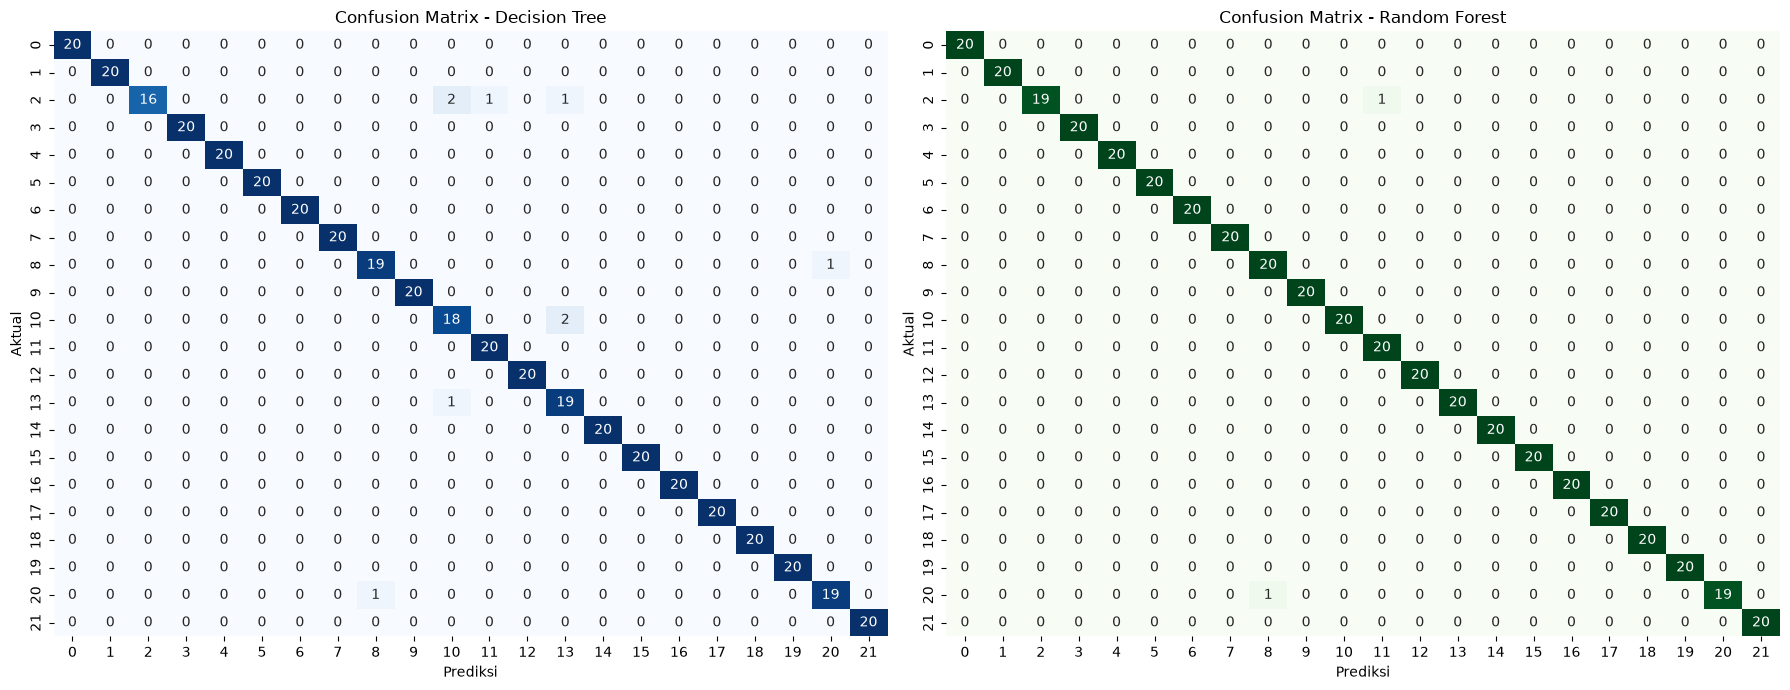

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Confusion Matrix Decision Tree
cm_dt = confusion_matrix(y_test, y_pred_dt)
sns.heatmap(
    cm_dt, annot=True, fmt="d", cmap="Blues",
    ax=axes[0], cbar=False
)
axes[0].set_title("Confusion Matrix - Decision Tree")
axes[0].set_xlabel("Prediksi")
axes[0].set_ylabel("Aktual")

# Confusion Matrix Random Forest
cm_rf = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(
    cm_rf, annot=True, fmt="d", cmap="Greens",
    ax=axes[1], cbar=False
)
axes[1].set_title("Confusion Matrix - Random Forest")
axes[1].set_xlabel("Prediksi")
axes[1].set_ylabel("Aktual")

plt.tight_layout()
plt.show()

# ANALISIS HASIL EVALUASI MODEL

In [11]:
# TABEL PERBANDINGAN HASIL EVALUASI

hasil_evaluasi = pd.DataFrame({
    "Metrik": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Decision Tree (%)": [
        accuracy_dt * 100,
        precision_dt * 100,
        recall_dt * 100,
        f1_dt * 100
    ],
    "Random Forest (%)": [
        accuracy_rf * 100,
        precision_rf * 100,
        recall_rf * 100,
        f1_rf * 100
    ]
})

# Menghitung selisih setiap metrik
hasil_evaluasi["Selisih (poin persentase)"] = (
    hasil_evaluasi["Random Forest (%)"]
    - hasil_evaluasi["Decision Tree (%)"]
)

display(hasil_evaluasi.round(2))

,Metrik,Decision Tree (%),Random Forest (%),Selisih (poin persentase)
0,Accuracy,97.95,99.55,1.59
1,Precision,98.06,99.57,1.51
2,Recall,97.95,99.55,1.59
3,F1-Score,97.94,99.55,1.60


# ANALISIS SELISIH ACCURACY

In [13]:
# ANALISIS SELISIH ACCURACY

selisih = (accuracy_rf - accuracy_dt) * 100

print("=" * 50)
print("ANALISIS SELISIH ACCURACY")
print("=" * 50)

print(f"Accuracy Decision Tree : {accuracy_dt * 100:.4f}%")
print(f"Accuracy Random Forest: {accuracy_rf * 100:.4f}%")
print(f"Selisih accuracy       : {selisih:.2f} poin persentase")

if accuracy_rf > accuracy_dt:
    print("\nKesimpulan:")
    print("Random Forest memiliki accuracy lebih tinggi.")
elif accuracy_dt > accuracy_rf:
    print("\nKesimpulan:")
    print("Decision Tree memiliki accuracy lebih tinggi.")
else:
    print("\nKesimpulan:")
    print("Kedua model memiliki accuracy yang sama.")

ANALISIS SELISIH ACCURACY
Accuracy Decision Tree : 97.9545%
Accuracy Random Forest: 99.5455%
Selisih accuracy       : 1.59 poin persentase

Kesimpulan:
Random Forest memiliki accuracy lebih tinggi.


### Analisis Perbandingan Hasil Evaluasi

Berdasarkan hasil pengujian pada 440 data testing, algoritma Decision Tree memperoleh accuracy sebesar 97,95%, sedangkan Random Forest mencapai accuracy sekitar 99,55%. Random Forest berhasil mengklasifikasikan 438 data dengan benar, sementara Decision Tree mengklasifikasikan 431 data dengan benar.

Selisih accuracy kedua model sebesar 1,59 poin persentase menunjukkan bahwa Random Forest memberikan hasil klasifikasi yang lebih baik pada pengujian awal. Keunggulan tersebut juga didukung oleh nilai precision, recall, dan F1-score yang lebih tinggi.

Meskipun demikian, hasil evaluasi ini hanya menggambarkan performa kedua model pada pembagian data yang digunakan. Oleh karena itu, diperlukan eksperimen parameter untuk mengetahui pengaruh konfigurasi model terhadap hasil klasifikasi dan menentukan model dengan performa yang paling baik.

# EKSPERIMEN DECISION TREE

In [14]:
# EKSPERIMEN PARAMETER DECISION TREE

depth_values = [None, 2, 3, 5]
dt_results = []

for depth in depth_values:

    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    # Melatih model
    model.fit(X_train, y_train)

    # Prediksi data testing
    pred = model.predict(X_test)

    # Menghitung evaluasi
    dt_results.append({
        "max_depth": str(depth),
        "Train Accuracy": model.score(X_train, y_train),
        "Test Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(
            y_test, pred,
            average="weighted",
            zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred,
            average="weighted",
            zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, pred,
            average="weighted",
            zero_division=0
        )
    })

# Menampilkan tabel hasil eksperimen
dt_results_df = pd.DataFrame(dt_results)

display(dt_results_df.round(4))

,max_depth,Train Accuracy,Test Accuracy,Precision,Recall,F1-Score
0,None,1.0000,0.9795,0.9806,0.9795,0.9794
1,2,0.1364,0.1364,0.0706,0.1364,0.0803
2,3,0.2273,0.2273,0.1618,0.2273,0.1717
3,5,0.4091,0.4068,0.2820,0.4068,0.3066


# GRAFIK HASIL EKSPERIMEN DECISION TREE

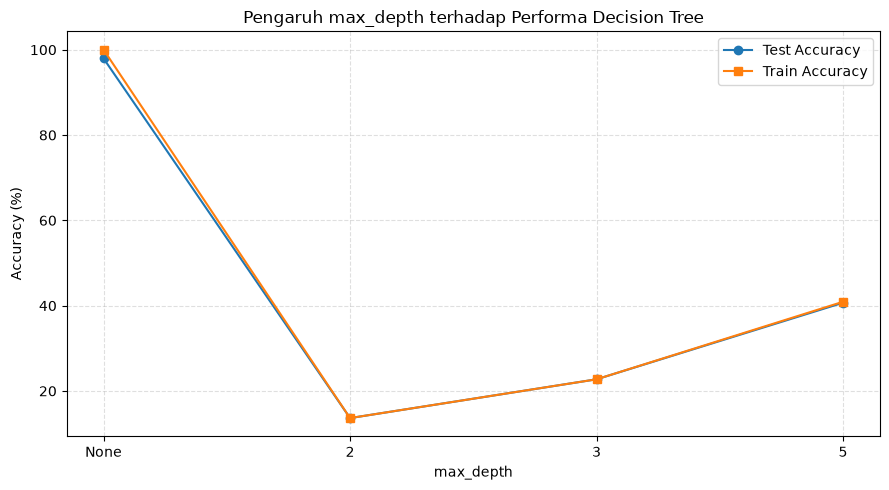

In [15]:
# GRAFIK EKSPERIMEN DECISION TREE

plt.figure(figsize=(9, 5))

plt.plot(
    dt_results_df["max_depth"],
    dt_results_df["Test Accuracy"] * 100,
    marker="o",
    label="Test Accuracy"
)

plt.plot(
    dt_results_df["max_depth"],
    dt_results_df["Train Accuracy"] * 100,
    marker="s",
    label="Train Accuracy"
)

plt.title("Pengaruh max_depth terhadap Performa Decision Tree")
plt.xlabel("max_depth")
plt.ylabel("Accuracy (%)")
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()

### Analisis Eksperimen Parameter Decision Tree

Berdasarkan hasil eksperimen, Decision Tree tanpa pembatasan kedalaman (`max_depth=None`) menghasilkan train accuracy sebesar 100% dan test accuracy sebesar 97,95%. Hasil ini menunjukkan bahwa model mampu mempelajari data training dengan baik dan menghasilkan performa tinggi pada data testing.

Ketika kedalaman pohon dibatasi menjadi 2, test accuracy turun menjadi 13,64%. Pada kedalaman 3, test accuracy meningkat menjadi 22,73%, sedangkan pada kedalaman 5 mencapai 40,68%. Peningkatan tersebut menunjukkan bahwa penambahan kedalaman membantu model mempelajari pola klasifikasi yang lebih kompleks.

Namun, seluruh model dengan pembatasan kedalaman masih menghasilkan akurasi yang lebih rendah dibandingkan model tanpa pembatasan. Hal ini menunjukkan bahwa pembatasan kedalaman yang terlalu ketat menyebabkan underfitting karena model belum mampu mempelajari karakteristik 22 jenis tanaman secara memadai.

Dengan demikian, pada eksperimen awal ini, Decision Tree tanpa pembatasan kedalaman memberikan hasil terbaik. Selanjutnya, diperlukan pengujian parameter Random Forest untuk membandingkan pengaruh jumlah pohon terhadap performa klasifikasi.

# EKSPERIMEN RANDOM FOREST

In [19]:
# EKSPERIMEN PARAMETER RANDOM FOREST

tree_values = [10, 50, 100, 200]
rf_results = []

for n in tree_values:

    model = RandomForestClassifier(
        n_estimators=n,
        random_state=42
    )

    # Melatih model
    model.fit(X_train, y_train)

    # Prediksi data testing
    pred = model.predict(X_test)

    # Menyimpan hasil evaluasi
    rf_results.append({
        "n_estimators": n,
        "Train Accuracy": model.score(X_train, y_train),
        "Test Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(
            y_test, pred,
            average="weighted",
            zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred,
            average="weighted",
            zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, pred,
            average="weighted",
            zero_division=0
        )
    })

# Menampilkan tabel hasil
rf_results_df = pd.DataFrame(rf_results)

display(rf_results_df.round(4))

,n_estimators,Train Accuracy,Test Accuracy,Precision,Recall,F1-Score
0,10,1.0,0.9932,0.9937,0.9932,0.9932
1,50,1.0,0.9955,0.9957,0.9955,0.9955
2,100,1.0,0.9955,0.9957,0.9955,0.9955
3,200,1.0,0.9955,0.9957,0.9955,0.9955


# GRAFIK EKSPERIMEN RANDOM FOREST

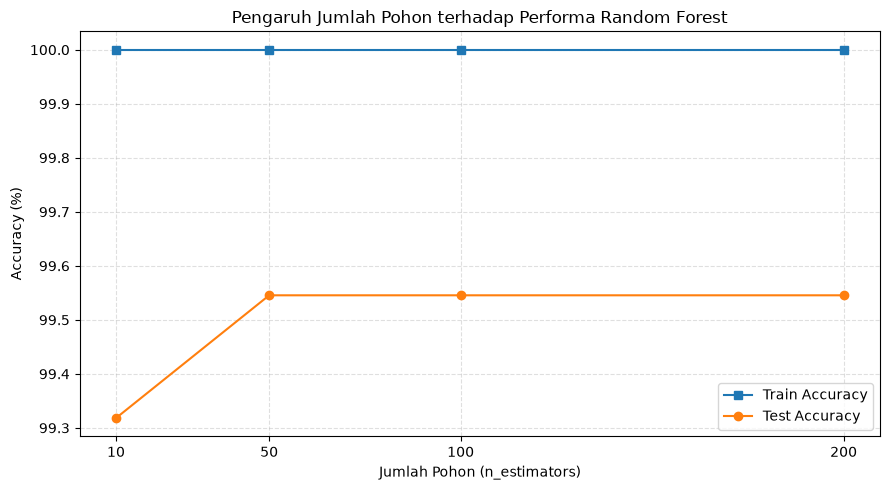

In [20]:
# GRAFIK PENGARUH JUMLAH POHON

plt.figure(figsize=(9, 5))

plt.plot(
    rf_results_df["n_estimators"],
    rf_results_df["Train Accuracy"] * 100,
    marker="s",
    label="Train Accuracy"
)

plt.plot(
    rf_results_df["n_estimators"],
    rf_results_df["Test Accuracy"] * 100,
    marker="o",
    label="Test Accuracy"
)

plt.title("Pengaruh Jumlah Pohon terhadap Performa Random Forest")
plt.xlabel("Jumlah Pohon (n_estimators)")
plt.ylabel("Accuracy (%)")
plt.xticks(tree_values)
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()

### Analisis Eksperimen Parameter Random Forest

Berdasarkan hasil eksperimen, Random Forest dengan 10 pohon keputusan memperoleh train accuracy sebesar 100% dan test accuracy sebesar 99,32%. Ketika jumlah pohon ditingkatkan menjadi 50, test accuracy meningkat menjadi 99,55%.

Pada konfigurasi 100 dan 200 pohon, test accuracy tetap sebesar 99,55%. Hasil ini menunjukkan bahwa penambahan jumlah pohon setelah mencapai 50 pohon tidak memberikan peningkatan accuracy pada pembagian data testing yang digunakan.

Dengan demikian, konfigurasi 50 pohon merupakan pilihan yang efisien di antara konfigurasi yang diuji karena menghasilkan accuracy testing yang sama dengan konfigurasi 100 dan 200 pohon, tetapi menggunakan jumlah pohon yang lebih sedikit. Namun, konfigurasi terbaik secara keseluruhan masih perlu mempertimbangkan kestabilan performa dan hasil pengujian lanjutan.

# Eksperimen max depth pada Random Forest

In [21]:
# EKSPERIMEN max_depth RANDOM FOREST

depth_values = [None, 2, 3, 5]
rf_depth_results = []

for depth in depth_values:
    model = RandomForestClassifier(
        n_estimators=100,
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    rf_depth_results.append({
        "max_depth": str(depth),
        "Train Accuracy": model.score(X_train, y_train),
        "Test Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(
            y_test, pred,
            average="weighted",
            zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred,
            average="weighted",
            zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, pred,
            average="weighted",
            zero_division=0
        )
    })

rf_depth_results_df = pd.DataFrame(rf_depth_results)
display(rf_depth_results_df.round(4))

,max_depth,Train Accuracy,Test Accuracy,Precision,Recall,F1-Score
0,None,1.0000,0.9955,0.9957,0.9955,0.9955
1,2,0.8693,0.8455,0.8095,0.8455,0.8021
2,3,0.9608,0.9500,0.9584,0.9500,0.9465
3,5,0.9932,0.9864,0.9876,0.9864,0.9863


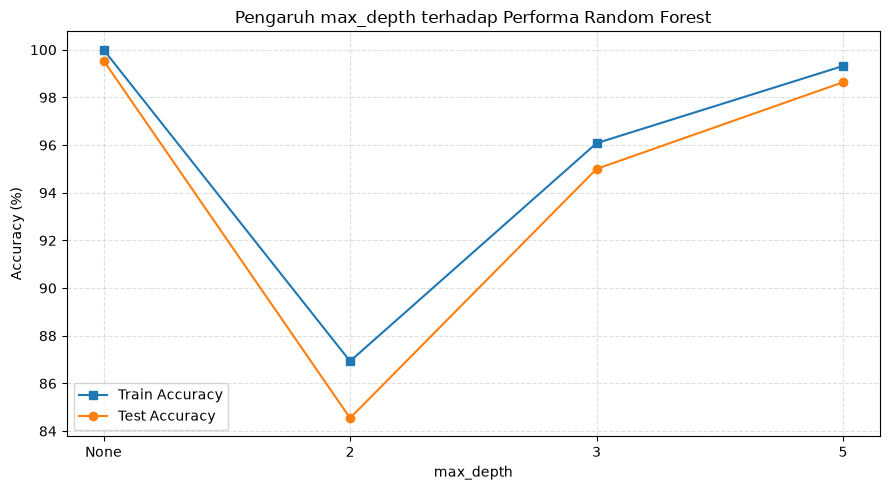

In [22]:
# GRAFIK PENGARUH max_depth RANDOM FOREST

plt.figure(figsize=(9, 5))

plt.plot(
    rf_depth_results_df["max_depth"],
    rf_depth_results_df["Train Accuracy"] * 100,
    marker="s",
    label="Train Accuracy"
)

plt.plot(
    rf_depth_results_df["max_depth"],
    rf_depth_results_df["Test Accuracy"] * 100,
    marker="o",
    label="Test Accuracy"
)

plt.title("Pengaruh max_depth terhadap Performa Random Forest")
plt.xlabel("max_depth")
plt.ylabel("Accuracy (%)")
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()

### Analisis Pengaruh max_depth pada Random Forest

Berdasarkan hasil eksperimen, Random Forest dengan parameter `max_depth=None` memperoleh train accuracy sebesar 100% dan test accuracy sebesar 99,55%. Ketika kedalaman pohon dibatasi menjadi 2, test accuracy menurun menjadi 84,55%. Pada kedalaman 3, accuracy meningkat menjadi 95,00%, kemudian mencapai 98,64% pada kedalaman 5.

Hasil tersebut menunjukkan bahwa pembatasan kedalaman pohon memengaruhi kemampuan model dalam mengenali pola pada dataset. Kedalaman yang terlalu rendah menyebabkan model kurang mampu membedakan karakteristik dari 22 jenis tanaman. Peningkatan kedalaman memberikan kesempatan kepada model untuk mempelajari pola yang lebih kompleks.

Konfigurasi tanpa pembatasan kedalaman memberikan hasil terbaik pada pengujian ini. Meskipun demikian, penentuan konfigurasi akhir perlu mempertimbangkan hasil cross-validation agar performa model dapat dinilai secara lebih konsisten.

# cross-validation

In [23]:
# 5-FOLD CROSS-VALIDATION

from sklearn.model_selection import StratifiedKFold, cross_val_score

# Membuat pembagian 5 fold
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Model Decision Tree
dt_cv_model = DecisionTreeClassifier(random_state=42)

scores_dt = cross_val_score(
    dt_cv_model,
    X,
    y,
    cv=cv,
    scoring="accuracy"
)

# Model Random Forest
rf_cv_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

scores_rf = cross_val_score(
    rf_cv_model,
    X,
    y,
    cv=cv,
    scoring="accuracy"
)

# Menampilkan hasil setiap fold
cv_results = pd.DataFrame({
    "Fold": [1, 2, 3, 4, 5],
    "Decision Tree": scores_dt,
    "Random Forest": scores_rf
})

display(cv_results.round(4))

print("Rata-rata Decision Tree:",
      round(scores_dt.mean() * 100, 2), "%")

print("Rata-rata Random Forest:",
      round(scores_rf.mean() * 100, 2), "%")

,Fold,Decision Tree,Random Forest
0,1,0.9818,0.9955
1,2,0.9932,0.9932
2,3,0.9932,1.0000
3,4,0.9773,0.9977
4,5,0.9932,0.9909


Rata-rata Decision Tree: 98.77 %
Rata-rata Random Forest: 99.55 %


### Analisis Hasil 5-Fold Cross-Validation

Berdasarkan hasil pengujian menggunakan 5-fold cross-validation, algoritma Decision Tree memperoleh rata-rata accuracy sebesar 98,77%, sedangkan Random Forest memperoleh rata-rata accuracy sebesar 99,55%.

Pada Decision Tree, accuracy tertinggi mencapai 99,32%, sedangkan accuracy terendah sebesar 97,73%. Sementara itu, Random Forest memperoleh accuracy tertinggi sebesar 100,00% dan terendah sebesar 99,09%. Hasil tersebut menunjukkan bahwa Random Forest memiliki rata-rata performa yang lebih tinggi dan variasi accuracy yang relatif lebih kecil pada lima fold yang diuji.

Dengan demikian, Random Forest menjadi algoritma dengan hasil cross-validation terbaik pada eksperimen ini. Namun, hasil tersebut perlu tetap diinterpretasikan sesuai dataset dan konfigurasi parameter yang digunakan.

# tabel akhir eksperimen

In [24]:
# TABEL RINGKASAN CROSS-VALIDATION

cv_summary = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],
    "Mean CV Accuracy (%)": [
        scores_dt.mean() * 100,
        scores_rf.mean() * 100
    ],
    "Std CV Accuracy (%)": [
        scores_dt.std() * 100,
        scores_rf.std() * 100
    ]
})

display(cv_summary.round(3))

,Model,Mean CV Accuracy (%),Std CV Accuracy (%)
0,Decision Tree,98.773,0.683
1,Random Forest,99.545,0.321


# HASIL VALIDASI AKHIR

# Visualisasi 1 — Perbandingan hasil cross-validation

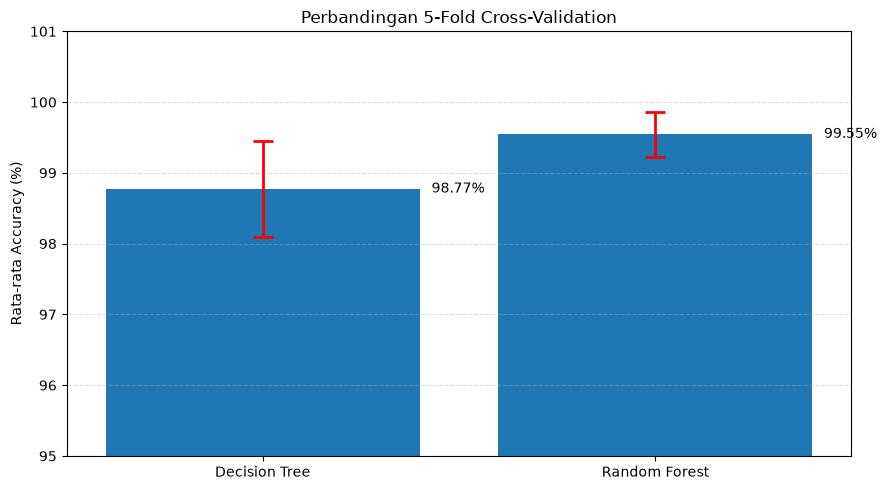

In [26]:
# VISUALISASI PERBANDINGAN 5-FOLD CROSS-VALIDATION

cv_models = ["Decision Tree", "Random Forest"]

cv_means = [
    scores_dt.mean() * 100,
    scores_rf.mean() * 100
]

cv_stds = [
    scores_dt.std() * 100,
    scores_rf.std() * 100
]

plt.figure(figsize=(9, 5))

bars = plt.bar(
    cv_models,
    cv_means,
    yerr=cv_stds,
    capsize=7,
    error_kw={
        "ecolor": "red",
        "elinewidth": 2,
        "capthick": 2
    }
)

plt.title("Perbandingan 5-Fold Cross-Validation")
plt.ylabel("Rata-rata Accuracy (%)")
plt.ylim(95, 101)
plt.grid(axis="y", linestyle="--", alpha=0.4)

# Menampilkan persentase di samping kanan batang
for bar, value in zip(bars, cv_means):
    plt.text(
        bar.get_x() + bar.get_width() + 0.03,
        bar.get_height(),
        f"{value:.2f}%",
        ha="left",
        va="center",
        fontsize=10
    )

plt.xlim(-0.5, 1.5)
plt.tight_layout()
plt.show()

# Visualisasi 2 — Feature Importance Random Forest

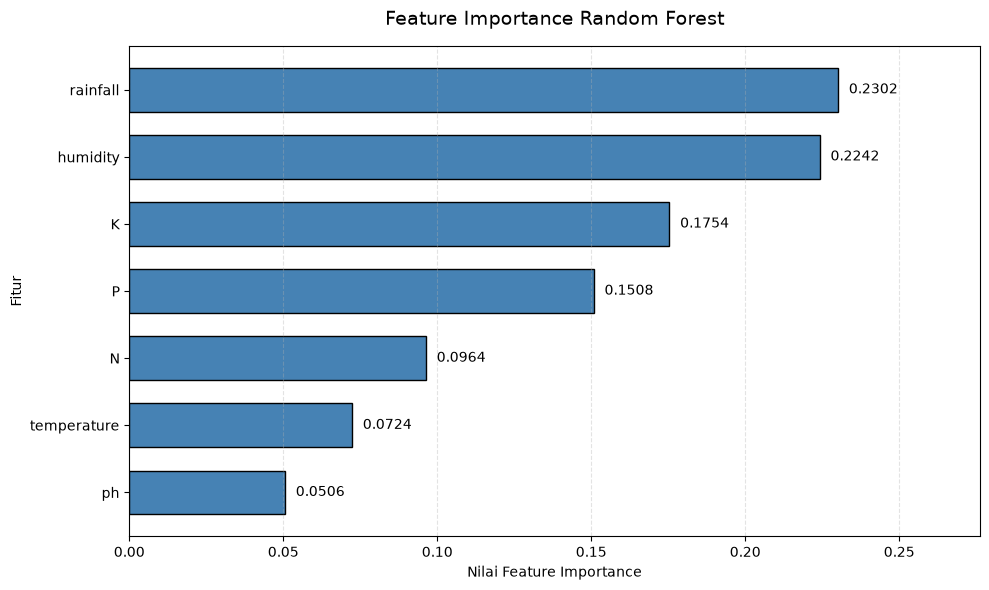

Urutan fitur dari yang paling penting:


,Fitur,Importance
0,rainfall,0.2302
1,humidity,0.2242
2,K,0.1754
3,P,0.1508
4,N,0.0964
5,temperature,0.0724
6,ph,0.0506


In [27]:
# VISUALISASI FEATURE IMPORTANCE RANDOM FOREST

# Mengambil nilai feature importance dari model
importance_df = pd.DataFrame({
    "Fitur": X.columns,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=True)

plt.figure(figsize=(10, 6))

bars = plt.barh(
    importance_df["Fitur"],
    importance_df["Importance"],
    color="steelblue",
    edgecolor="black",
    height=0.65
)

# Memberikan ruang untuk label di sisi kanan
plt.xlim(0, importance_df["Importance"].max() * 1.20)

# Menampilkan nilai importance di samping batang
for bar, value in zip(bars, importance_df["Importance"]):
    plt.text(
        value + importance_df["Importance"].max() * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.4f}",
        va="center",
        ha="left",
        fontsize=10
    )

plt.title(
    "Feature Importance Random Forest",
    fontsize=14,
    pad=15
)
plt.xlabel("Nilai Feature Importance")
plt.ylabel("Fitur")
plt.grid(axis="x", linestyle="--", alpha=0.35)
plt.tight_layout()
plt.show()

# Menampilkan tabel urutan fitur
print("Urutan fitur dari yang paling penting:")
display(
    importance_df.sort_values(
        "Importance", ascending=False
    ).reset_index(drop=True).round(4)
)

# Visualisasi 3 — Confusion Matrix Random Forest

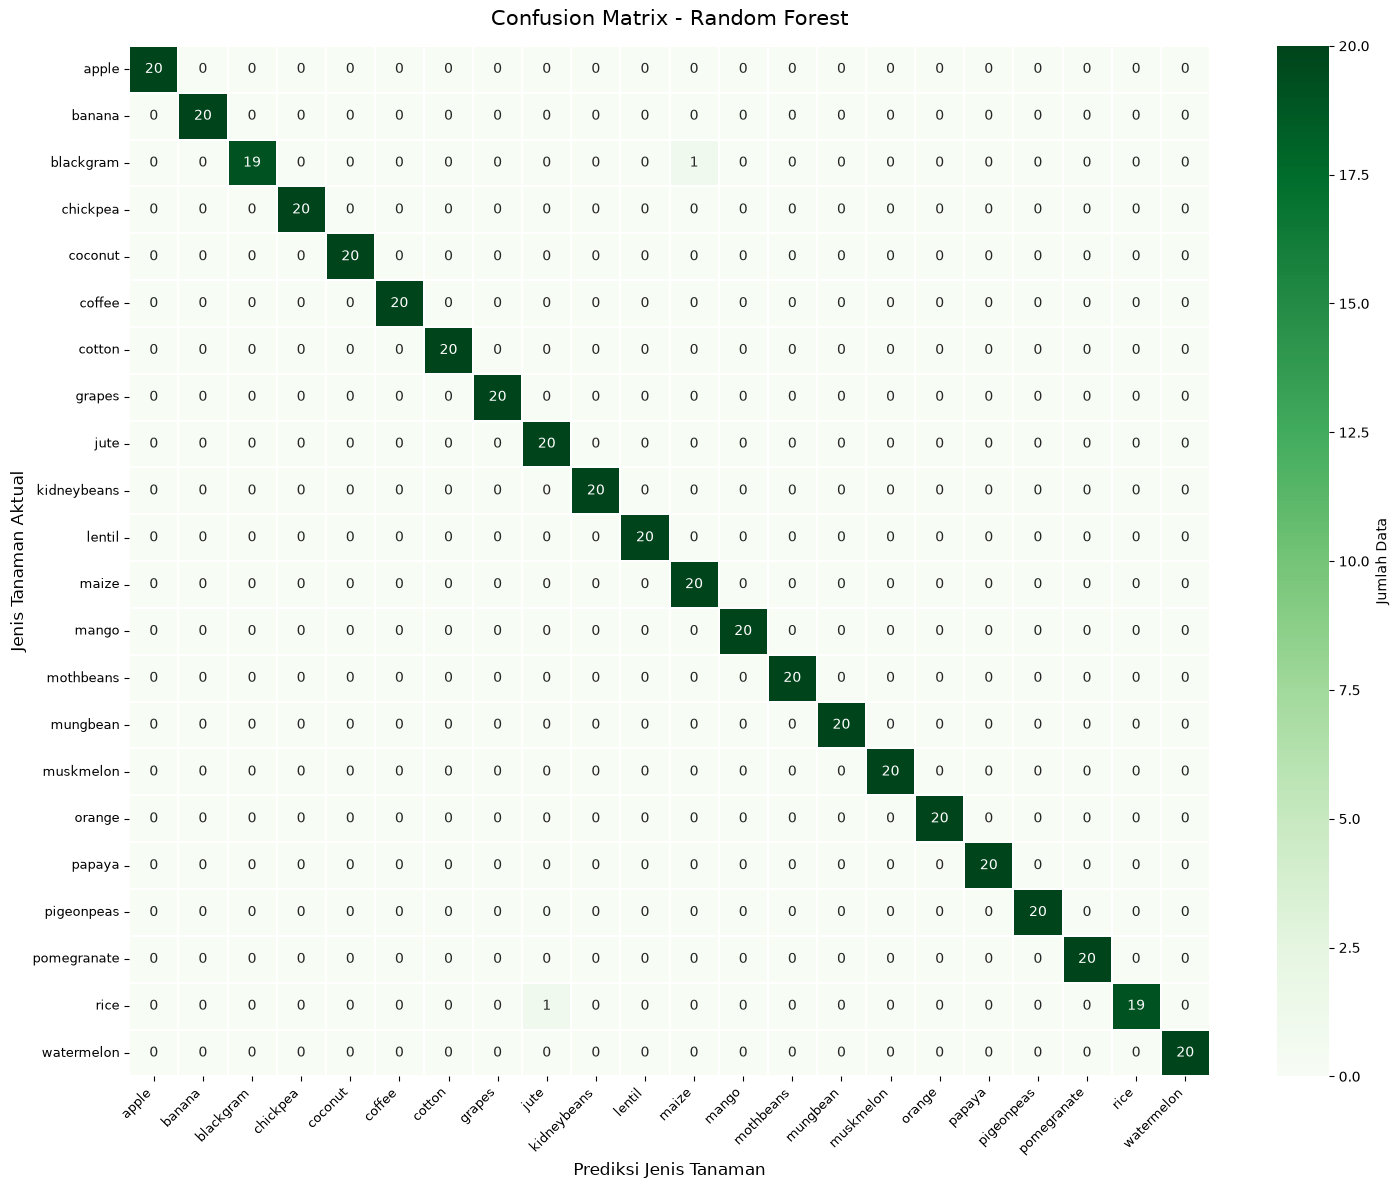

In [28]:
# VISUALISASI CONFUSION MATRIX RANDOM FOREST

labels = rf_model.classes_

cm = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=labels
)

plt.figure(figsize=(15, 12))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    linewidths=0.3,
    linecolor="white",
    xticklabels=labels,
    yticklabels=labels,
    cbar_kws={
        "label": "Jumlah Data"
    }
)

plt.title(
    "Confusion Matrix - Random Forest",
    fontsize=15,
    pad=15
)
plt.xlabel("Prediksi Jenis Tanaman", fontsize=12)
plt.ylabel("Jenis Tanaman Aktual", fontsize=12)

plt.xticks(rotation=45, ha="right", fontsize=9)
plt.yticks(rotation=0, fontsize=9)

plt.tight_layout()
plt.show()